# DQN — mô phỏng lựa chọn chủ đề giáo dục

Dữ liệu là trạng thái tạo ngẫu nhiên trong môi trường mô phỏng, không phải hồ sơ bệnh nhân. Đây là notebook huấn luyện DQN riêng, không ghi đè mô hình website.

## 1. Thiết lập

In [1]:
EXPERIMENT='rl_education'
import os, json, hashlib, random, sys, platform
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, brier_score_loss)
import torch
from torch import nn
import joblib
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'docker-compose.yml').exists()), None)
if ROOT is None: raise RuntimeError('Chạy notebook trong thư mục dự án.')
SMOKE = os.getenv('NOTEBOOK_SMOKE') == '1'  # Chỉ dùng cho kiểm thử kỹ thuật, không báo cáo kết quả.
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(1)
run_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN_DIR = (Path('/tmp/duongan_notebook_smoke') if SMOKE else ROOT/'artifacts/notebook_runs') / EXPERIMENT / run_stamp
RUN_DIR.mkdir(parents=True, exist_ok=False)
print('Project:', ROOT, '| kết quả:', RUN_DIR, '| kiểm thử nhanh:', SMOKE)
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import DQN

Project: /app | kết quả: /app/artifacts/notebook_runs/rl_education/20261105T082005_333033Z | kiểm thử nhanh: False


## 2. Biểu diễn dữ liệu và phân tích
Không có tệp dữ liệu thật: khảo sát toàn bộ 16 trạng thái nhị phân, số chủ đề còn thiếu và phân bố của chúng.

 Tổng quan  Ăn uống  Vận động  Theo dõi  so_chu_de_can_hoc
         0        0         0         0                  0
         0        0         0         1                  1
         0        0         1         0                  1
         0        0         1         1                  2
         0        1         0         0                  1
         0        1         0         1                  2
         0        1         1         0                  2
         0        1         1         1                  3
         1        0         0         0                  1
         1        0         0         1                  2
         1        0         1         0                  2
         1        0         1         1                  3
         1        1         0         0                  2
         1        1         0         1                  3
         1        1         1         0                  3
         1        1         1         1                 

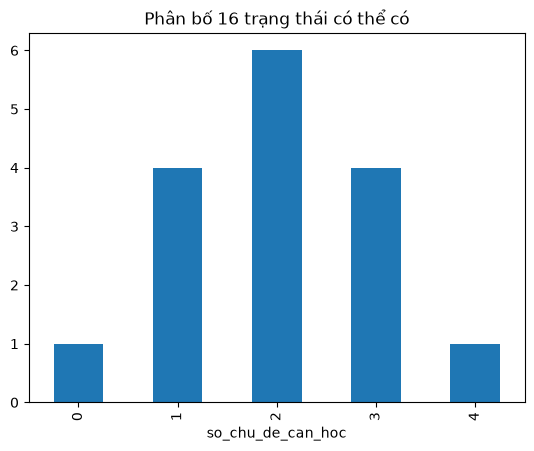

In [2]:
from itertools import product
states=np.array(list(product([0,1],repeat=4)),dtype=np.int8)
state_frame=pd.DataFrame(states,columns=['Tổng quan','Ăn uống','Vận động','Theo dõi'])
state_frame['so_chu_de_can_hoc']=states.sum(axis=1)
print(state_frame.to_string(index=False))
state_frame.so_chu_de_can_hoc.value_counts().sort_index().plot.bar(title='Phân bố 16 trạng thái có thể có'); plt.show()

## 3. Làm sạch và kiểm tra dữ liệu mô phỏng
Kiểm tra miền trạng thái và hành động; không có missing hoặc dữ liệu y tế được suy ra.

In [3]:
assert states.shape==(16,4) and np.isin(states,[0,1]).all()
assert len(np.unique(states,axis=0))==16
print('16 trạng thái duy nhất, 4 biến nhị phân; không có giá trị thiếu.')

16 trạng thái duy nhất, 4 biến nhị phân; không có giá trị thiếu.


In [4]:
TOPICS = [
    'Tổng quan về tiểu đường',
    'Ăn uống cân bằng',
    'Vận động thể chất',
    'Theo dõi sức khỏe'
]

In [5]:
class EducationEnv(gym.Env):
    """
    Simulated educational environment.
    State: MultiBinary(4) where 1 indicates an unlearned module, 0 indicates completed.
    Action: Discrete(4) corresponding to selecting one module to deliver.
    Reward: +1.0 if the selected module was needed (state[a] == 1).
            -0.25 if the module was already completed (state[a] == 0).
    Episode ends after 4 interaction steps or when all topics are completed.
    """
    def __init__(self):
        super().__init__()
        self.observation_space = spaces.MultiBinary(4)
        self.action_space = spaces.Discrete(4)
        self.state = np.zeros(4, dtype=np.int8)
        self.steps = 0

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        # Generate random initial needs
        self.state = self.np_random.integers(0, 2, size=4, dtype=np.int8)
        self.steps = 0
        return self.state.copy(), {}

    def step(self, action: int):
        # If all topics already learned, action cannot provide new value
        all_done_before = bool(np.all(self.state == 0))
        
        if self.state[action] == 1:
            reward = 1.0
            self.state[action] = 0  # Marked as learned
        else:
            reward = 0.0 if all_done_before else -0.25
            
        self.steps += 1
        terminated = bool(self.steps >= 4 or np.all(self.state == 0))
        truncated = False
        return self.state.copy(), float(reward), terminated, truncated, {}

In [6]:
def evaluate_policy(policy_fn, episodes=200, base_seed=10000):
    env = EducationEnv()
    returns = []
    for ep in range(episodes):
        seed = base_seed + ep
        obs, _ = env.reset(seed=seed)
        total_reward = 0.0
        for step in range(4):
            action = policy_fn(obs, seed, step)
            obs, reward, terminated, truncated, _ = env.step(int(action))
            total_reward += reward
            if terminated or truncated:
                break
        returns.append(total_reward)
    return float(np.mean(returns)), float(np.std(returns))

In [7]:
def greedy_heuristic(obs, seed, step):
    unlearned = np.where(obs == 1)[0]
    return unlearned[0] if len(unlearned) > 0 else 0

In [8]:
def random_policy(obs, seed, step):
    rng = np.random.default_rng(seed * 31 + step)
    return int(rng.integers(4))

## 4. Huấn luyện và quan sát hội tụ DQN
RL không có epoch dữ liệu như phân loại. Huấn luyện mỗi seed trong 30.000 bước; đánh giá theo từng checkpoint 5.000 bước trên seed validation cố định. Chạy ba seed khởi tạo và chọn checkpoint tốt nhất theo reward validation. Reward chỉ là giả lập.

seed=42 buoc=5000 reward validation=1.9900


seed=42 buoc=10000 reward validation=1.9900


seed=42 buoc=15000 reward validation=1.9900


seed=42 buoc=20000 reward validation=1.9900


seed=42 buoc=25000 reward validation=1.9900


seed=42 buoc=30000 reward validation=1.9900


... (8 outputs left out)

seed=44 buoc=15000 reward validation=1.9900


seed=44 buoc=20000 reward validation=1.9900


seed=44 buoc=25000 reward validation=1.9900


seed=44 buoc=30000 reward validation=1.9900


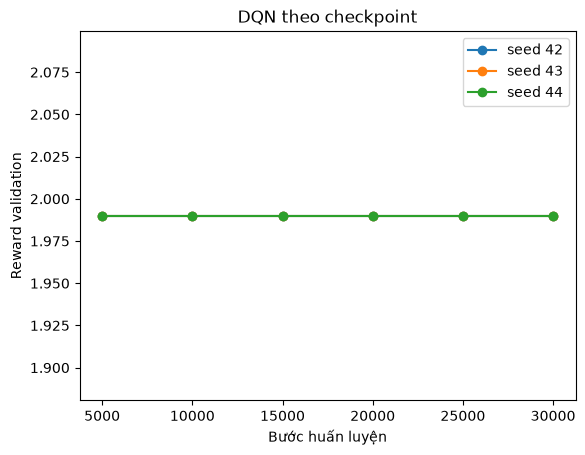

Seed và checkpoint tốt nhất theo validation: [(42, 5000, 1.99), (43, 5000, 1.99), (44, 5000, 1.99)]


In [9]:
seeds=[42] if SMOKE else [42,43,44]
val_seeds=[6000,7000]; test_seeds=[1000,2000,3000,4000,5000]
assert set(val_seeds).isdisjoint(test_seeds)
episodes=10 if SMOKE else 100
steps_per_check=500 if SMOKE else 5000
checkpoints=1 if SMOKE else 6
runs=[]
for run_seed in seeds:
    random.seed(run_seed); np.random.seed(run_seed); torch.manual_seed(run_seed)
    env=EducationEnv()
    model=DQN('MlpPolicy',env,seed=run_seed,learning_starts=200,buffer_size=10000,batch_size=64,gamma=.99,verbose=0)
    best_return=-float('inf'); best_step=0; best_model=None; curve=[]
    for check in range(1,checkpoints+1):
        model.learn(total_timesteps=steps_per_check,reset_num_timesteps=False)
        policy=lambda obs,seed,step: model.predict(obs,deterministic=True)[0]
        mean=float(np.mean([evaluate_policy(policy,episodes=episodes,base_seed=s)[0] for s in val_seeds]))
        curve.append({'steps':check*steps_per_check,'validation_return':mean})
        if mean>best_return:
            import copy
            best_model=copy.deepcopy(model); best_return=mean; best_step=check*steps_per_check
        print(f'seed={run_seed} buoc={check*steps_per_check} reward validation={mean:.4f}',flush=True)
    runs.append({'seed':run_seed,'model':best_model,'curve':curve,'best_step':best_step,'validation_return':best_return})
for run in runs:
    curve=pd.DataFrame(run['curve']);plt.plot(curve.steps,curve.validation_return,marker='o',label=f"seed {run['seed']}")
plt.xlabel('Bước huấn luyện');plt.ylabel('Reward validation');plt.title('DQN theo checkpoint');plt.legend();plt.show()
print('Seed và checkpoint tốt nhất theo validation:',[(r['seed'],r['best_step'],r['validation_return']) for r in runs])

## 5. So sánh validation và lựa chọn
So sánh ba seed DQN với greedy và random trên cùng seed validation; chọn reward trung bình cao nhất, ưu tiên greedy nếu bằng nhau. Việc chọn seed/checkpoint theo validation có thể quá khớp validation.

In [10]:
policies={'greedy':greedy_heuristic,'random':random_policy}
for run in runs:
    def policy(obs, seed, step, candidate=run['model']): return candidate.predict(obs,deterministic=True)[0]
    policies[f"dqn_seed_{run['seed']}"]=policy
val_results={name:float(np.mean([evaluate_policy(fn,episodes=episodes,base_seed=s)[0] for s in val_seeds])) for name,fn in policies.items()}
selected=max(policies,key=lambda name:val_results[name])
print(pd.DataFrame.from_dict(val_results,orient='index',columns=['validation_reward']).sort_values('validation_reward',ascending=False).to_string())
print('Chính sách được chọn:',selected)

             validation_reward
greedy                 1.99000
dqn_seed_42            1.99000
dqn_seed_43            1.99000
dqn_seed_44            1.99000
random                 0.94875
Chính sách được chọn: greedy


## 6. Đánh giá test
Dùng seed test khác validation cho chính sách đã chọn; kết quả mô phỏng không đo lợi ích lâm sàng hay giáo dục thực tế. Các seed test đã được xem ở lần chạy trước.

Test mean reward: 2.026 | mean theo từng seed: [2.105, 2.005, 1.985, 2.005, 2.03]


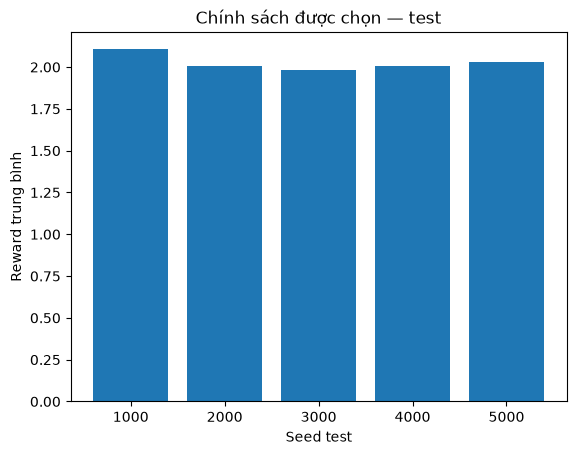

In [11]:
test_episodes=10 if SMOKE else 200
test_returns=[evaluate_policy(policies[selected],episodes=test_episodes,base_seed=s)[0] for s in test_seeds]
print('Test mean reward:',float(np.mean(test_returns)),'| mean theo từng seed:',test_returns)
plt.bar([str(s) for s in test_seeds],test_returns);plt.xlabel('Seed test');plt.ylabel('Reward trung bình');plt.title('Chính sách được chọn — test');plt.show()

## 7. Lưu thí nghiệm
Lưu ba checkpoint DQN tốt nhất theo validation, đường reward và lựa chọn; không thay model website.

In [12]:
report={'experiment':EXPERIMENT,'seeds':seeds,'smoke_test':SMOKE,
 'training_steps_per_seed':steps_per_check*checkpoints,'validation_seeds':val_seeds,'test_seeds':test_seeds,
 'validation_episodes_per_seed':episodes,'test_episodes_per_seed':test_episodes,'validation_returns':val_results,
 'selection_rule':'highest validation reward; tie prefer first candidate greedy',
 'selected_policy':selected,'test_selected_mean_return':float(np.mean(test_returns)),
 'test_seed_returns':test_returns,
 'dqn_runs':[{'seed':r['seed'],'best_step':r['best_step'],'validation_return':r['validation_return'],'curve':r['curve']} for r in runs],
 'warning':'Synthetic education reward; test seeds previously inspected; not clinical.'}
(RUN_DIR/'report.json').write_text(json.dumps(report,indent=2,ensure_ascii=False)+'\n',encoding='utf-8')
for run in runs: run['model'].save(str(RUN_DIR/f"dqn_seed_{run['seed']}"))
print('Lưu tại',RUN_DIR)

Lưu tại /app/artifacts/notebook_runs/rl_education/20261105T082005_333033Z
